# What does a rotation-only fit return when the star also has macroturbulence?

Spectroscopic surveys at low resolution (e.g. SDSS-V BOSS, R ≈ 2000) often fit the line broadening of OB stars with
rotation alone. Real OB-star lines are also broadened by **macroturbulence**, a large-scale photospheric velocity field
of typically 20–100 km/s. The fitted $v\sin i$ then absorbs both. This notebook works out, step by step, how the
fitted value depends on the true $v\sin i$ and the macroturbulent velocity $\zeta$.

The result is

$$
v\sin i_\mathrm{fit} \simeq \sqrt{(v\sin i)^2 + k^2\zeta^2},
$$

with $k \approx 0.75$ at high resolution and $k \approx 0.8$–$0.9$ at R = 2000, for equal radial and
tangential macroturbulence (Section 8 shows how $k$ changes otherwise). The steps:

1. The rotation kernel.
2. The radial-tangential macroturbulence model.
3. Building a disk-integrated line profile.
4. Why widths add in quadrature: the second moments, derived exactly.
5. What a least-squares rotation-only fit actually returns, and the value of $k$.
6. The same at BOSS resolution with noise.
7. Does low resolution create a pile-up of fitted values?
8. How much the result depends on the assumed ratio of radial to tangential motions.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve

plt.rc('font', family='serif'); plt.rc('axes', labelsize=10)
plt.rc('xtick', top=True, direction='out'); plt.rc('ytick', right=True, direction='out')

C_KMS = 2.998e5
dv = 1.0                                   # velocity grid step (km/s)
V = np.arange(-900., 900.01, dv)           # velocity grid (km/s)

def gauss(v, c, w):
    # unit-area Gaussian centred on c with 1/e half-width w (km/s)
    return np.exp(-((v - c) / w)**2) / (np.sqrt(np.pi) * w)

def conv(a, b):
    return fftconvolve(a, b, mode='same')

## 1. The rotation kernel

A rigidly rotating star seen at inclination $i$ has, at projected position $x$ (in units of the stellar radius, measured
from the projected rotation axis), a line-of-sight velocity $x\,v\sin i$. All points on the disk with the same $x$ shift
the line by the same amount, so the flux profile of an infinitely narrow line is the intensity integrated along strips
of constant $x$. With a linear limb-darkening law $I(\mu) = I_0(1-\varepsilon+\varepsilon\mu)$, where $\mu=\cos\theta$, the
result is the classical rotation kernel (Gray, *The Observation and Analysis of Stellar Photospheres*):

$$
G(x) \propto 2(1-\varepsilon)\sqrt{1-x^2} + \frac{\pi\varepsilon}{2}(1-x^2), \qquad |x|<1,\quad x = v/v\sin i .
$$

We use $\varepsilon = 0.6$, typical of the optical continuum of hot stars.

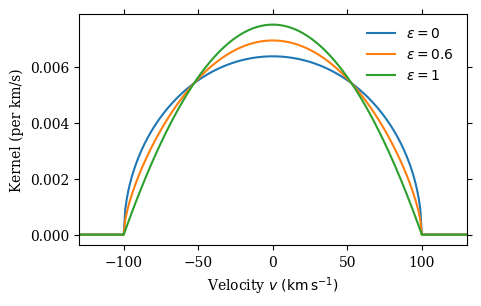

In [2]:
EPS = 0.6

def rot_kernel(vsini, eps=EPS):
    # rotation kernel on the grid V, normalised to unit sum
    if vsini < 0.5:
        k = np.zeros_like(V); k[len(V) // 2] = 1; return k
    x = V / vsini
    k = np.where(np.abs(x) < 1,
                 2 * (1 - eps) * np.sqrt(np.clip(1 - x**2, 0, None)) + np.pi * eps / 2 * (1 - x**2), 0)
    return k / k.sum()

fig, ax = plt.subplots(figsize=(5, 3))
for e in [0, 0.6, 1]:
    ax.plot(V, rot_kernel(100, e) / dv, label=rf'$\varepsilon={e}$')
ax.set_xlim(-130, 130); ax.set_xlabel(r'Velocity $v~(\mathrm{km\,s^{-1}})$'); ax.set_ylabel('Kernel (per km/s)')
ax.legend(frameon=False); plt.show()

The kernel has sharp edges at $\pm v\sin i$. Limb darkening makes it more peaked: the bright disk centre moves slowly.

## 2. Radial-tangential macroturbulence

In the radial-tangential model (Gray), a fraction $A_R$ of the surface moves along the local radius and a fraction
$A_T = 1 - A_R$ moves along the surface, each with a Gaussian distribution of speeds of 1/e width $\zeta$. At a point
where the line of sight makes an angle $\theta$ with the local normal ($\mu=\cos\theta$), the projection onto the line of
sight gives

* radial cells: a Gaussian of 1/e width $\zeta\mu$, i.e. variance $\zeta^2\mu^2/2$;
* tangential cells: a Gaussian of 1/e width $\zeta\sqrt{1-\mu^2}$, i.e. variance $\zeta^2(1-\mu^2)/2$.

So the local macroturbulent profile changes across the disk: at disk centre only the radial motions are seen, at the
limb only the tangential ones. We take $A_R = A_T = 1/2$, the usual choice in OB-star analyses (e.g. the IACOB
measurements of $v_\mathrm{mac}$).

## 3. A disk-integrated line profile

We assume a **weak line**: the flux profile is the intensity-weighted sum over the visible disk of the local profiles,
each shifted by the local rotational velocity. The local profile is the intrinsic profile (thermal plus
microturbulent, a Gaussian of 1/e width $w_0 = 15$ km/s, roughly He at 30 kK with 10 km/s microturbulence) convolved
with the local macroturbulence. The convolution of two Gaussians is a Gaussian whose squared widths add, so each disk
element contributes two Gaussians, one radial and one tangential.

Note that rotation and macroturbulence are *not* simply convolved here: the macroturbulent width depends on $\mu$, and
$\mu$ is correlated with the rotational shift $x$. The full disk integration keeps this.

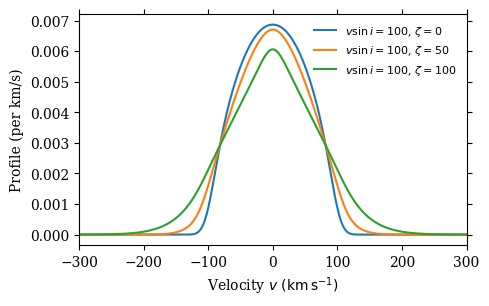

In [3]:
W0 = 15.0                                   # intrinsic 1/e half-width (km/s)

# Cartesian grid over the projected disk
n = 161
g = np.linspace(-1, 1, n)
X2, Y2 = np.meshgrid(g, g)
on = X2**2 + Y2**2 < 1
X, MU = X2[on], np.sqrt(1 - X2[on]**2 - Y2[on]**2)
WT = 1 - EPS + EPS * MU; WT /= WT.sum()     # limb-darkened intensity weights

def disk_profile(vsini, zeta, A_R=0.5, chunk=1500):
    # weak-line flux profile (unit area): rotation + radial-tangential macroturbulence + intrinsic Gaussian
    out = np.zeros_like(V)
    wR = np.sqrt(W0**2 + (zeta * MU)**2)                 # radial cells
    wT = np.sqrt(W0**2 + zeta**2 * (1 - MU**2))          # tangential cells
    for i in range(0, X.size, chunk):
        s = slice(i, i + chunk); c = (X[s] * vsini)[:, None]
        loc = A_R * gauss(V[None], c, wR[s][:, None]) + (1 - A_R) * gauss(V[None], c, wT[s][:, None])
        out += (WT[s][:, None] * loc).sum(0)
    return out * dv

fig, ax = plt.subplots(figsize=(5, 3))
for z in [0, 50, 100]:
    ax.plot(V, disk_profile(100, z) / dv, label=rf'$v\sin i=100$, $\zeta={z}$')
ax.set_xlim(-300, 300); ax.set_xlabel(r'Velocity $v~(\mathrm{km\,s^{-1}})$'); ax.set_ylabel('Profile (per km/s)')
ax.legend(frameon=False, fontsize=8); plt.show()

Macroturbulence makes the profile more pointed in the core and adds extended wings, while keeping its area. A fit with rotation alone has
to absorb this extra width by increasing $v\sin i$.

## 4. Why the widths add in quadrature: second moments

The **second moment** (the velocity variance) of a profile is additive under convolution:
$\sigma^2_{a*b} = \sigma^2_a + \sigma^2_b$. For the weak-line disk integral above the same holds exactly, even without
a convolution, because the variance of a mixture of shifted local profiles is the weighted mean of
(shift² + local variance), and both terms are averaged with the same disk weights. So

$$
\sigma^2_\mathrm{obs} = \sigma^2_\mathrm{rot} + \sigma^2_\mathrm{mac} + \sigma^2_\mathrm{intrinsic} + \sigma^2_\mathrm{instrument}.
$$

We compute the two pieces we need with sympy.

**Rotation.** $\sigma^2_\mathrm{rot} = m_2(\varepsilon)\,(v\sin i)^2$ with $m_2 = \int x^2 G\,dx / \int G\,dx$.

In [4]:
x, eps, mu, zeta, AR = sp.symbols('x epsilon mu zeta A_R', positive=True)
G = 2 * (1 - eps) * sp.sqrt(1 - x**2) + sp.pi * eps / 2 * (1 - x**2)
m2 = sp.simplify(sp.integrate(x**2 * G, (x, -1, 1)) / sp.integrate(G, (x, -1, 1)))
display(sp.Eq(sp.Symbol('m_2'), sp.factor(m2)))
print('m2(eps=0)   =', m2.subs(eps, 0))
print('m2(eps=0.6) =', sp.N(m2.subs(eps, sp.Rational(3, 5)), 4))

Eq(m_2, (7*epsilon - 15)/(20*(epsilon - 3)))

m2(eps=0)   = 1/4
m2(eps=0.6) = 0.2250


As a check, the same moment computed directly as an integral over the limb-darkened disk (polar coordinates $r,\phi$
on the projected disk, $x = r\cos\phi$, $\mu=\sqrt{1-r^2}$) must agree:

In [5]:
r, phi = sp.symbols('r phi', positive=True)
mu_d = sp.sqrt(1 - r**2); I = 1 - eps + eps * mu_d
num = sp.integrate(sp.integrate((r * sp.cos(phi))**2 * I * r, (phi, 0, 2 * sp.pi)), (r, 0, 1))
den = sp.integrate(sp.integrate(I * r, (phi, 0, 2 * sp.pi)), (r, 0, 1))
print('disk integral - kernel moment =', sp.simplify(num / den - m2))

disk integral - kernel moment = 0


**Macroturbulence.** The local line-of-sight variance is $A_R\,\zeta^2\mu^2/2 + A_T\,\zeta^2(1-\mu^2)/2$. For
$A_R = A_T = 1/2$:

In [6]:
var_local = AR * zeta**2 * mu**2 / 2 + (1 - AR) * zeta**2 * (1 - mu**2) / 2
print('A_R = 1/2 :', sp.simplify(var_local.subs(AR, sp.Rational(1, 2))))
print('A_R = 0.7 :', sp.simplify(var_local.subs(AR, sp.Rational(7, 10))), '   (depends on mu: no longer weighting-independent)')

A_R = 1/2 : zeta**2/4
A_R = 0.7 : zeta**2*(4*mu**2 + 3)/20    (depends on mu: no longer weighting-independent)


With equal radial and tangential fractions the local variance is $\zeta^2/4$ at *every* point of the disk, so the
disk average is $\sigma^2_\mathrm{mac} = \zeta^2/4$, independent of limb darkening.

**Putting it together.** If a rotation-only fit reproduced the total variance, it would return

$$
m_2 (v\sin i_\mathrm{fit})^2 = m_2 (v\sin i)^2 + \frac{\zeta^2}{4}
\quad\Rightarrow\quad
v\sin i_\mathrm{fit} = \sqrt{(v\sin i)^2 + k_\sigma^2\zeta^2},\qquad k_\sigma = \frac{1}{2\sqrt{m_2}} .
$$

This is the origin of the quadrature form.

In [7]:
k_sigma = 1 / (2 * sp.sqrt(m2))
print('k_sigma(eps=0)   =', sp.N(k_sigma.subs(eps, 0), 3))
print('k_sigma(eps=0.6) =', sp.N(k_sigma.subs(eps, sp.Rational(3, 5)), 3))

k_sigma(eps=0)   = 1.00
k_sigma(eps=0.6) = 1.05


We can also verify the additivity numerically on the profiles of Section 3: the variance of the full profile minus
the variance with $\zeta = 0$ should equal $\zeta^2/4$.

In [8]:
def variance(p):
    p = p / p.sum(); m = (V * p).sum(); return ((V - m)**2 * p).sum()

for vs, z in [(100, 40), (100, 80), (200, 60)]:
    d = variance(disk_profile(vs, z)) - variance(disk_profile(vs, 0))
    print(f'vsini={vs:3d}, zeta={z:3d}:  measured extra variance = {d:7.1f}   zeta^2/4 = {z**2 / 4:7.1f}')

vsini=100, zeta= 40:  measured extra variance =   400.0   zeta^2/4 =   400.0


vsini=100, zeta= 80:  measured extra variance =  1600.0   zeta^2/4 =  1600.0


vsini=200, zeta= 60:  measured extra variance =   900.0   zeta^2/4 =   900.0


## 5. What a least-squares fit actually returns

A real fit does not match variances. It minimises the squared residuals, which are dominated by the line core. The
macroturbulent profile has extended, low wings that carry a large share of its variance but little weight in the
fit. So we expect the fitted $k$ to be **smaller** than $k_\sigma \approx 1.05$.

To measure it we build "observed" profiles with the full model (rotation + macroturbulence + intrinsic + instrument),
sample them on pixels, and fit them with a rotation-only model (rotation kernel ⊗ intrinsic ⊗ instrument). The free
parameters are $v\sin i$ and the line strength. The line strength enters linearly, so for each trial $v\sin i$ on a fine
grid we solve for it exactly and keep the $v\sin i$ with the smallest $\chi^2$.

Line strength: equivalent width 60 km/s (≈ 0.9 Å at 4471 Å). The continuum is 1, so the arrays below are line depths.

In [9]:
EW = 60.0                                   # equivalent width (km/s)
G0 = gauss(V, 0, W0) * dv                   # intrinsic profile, unit sum

def instrument(R):
    fwhm = C_KMS / R
    return gauss(V, 0, fwhm / (2 * np.sqrt(np.log(2)))) * dv

def pixels(pix):
    return np.arange(len(V) // 2 % pix, len(V), pix)   # pixel centres, one on v = 0

def model_table(R, idx, vgrid=np.arange(0, 600.01, 0.25)):
    # rotation-only templates, one row per trial vsini, sampled at the pixels
    T = np.array([conv(conv(rot_kernel(v), G0), instrument(R))[idx] for v in vgrid])
    return vgrid, T

def fit_vsini(obs, vgrid, T):
    a = T @ obs / np.einsum('ij,ij->i', T, T)                    # best line strength at each trial vsini
    resid = T * a[:, None] - obs
    return vgrid[np.argmin(np.einsum('ij,ij->i', resid, resid))]

def observe(vsini, zeta, R, idx):
    return EW * conv(disk_profile(vsini, zeta), instrument(R))[idx]

One example first: $v\sin i = 100$ km/s, $\zeta = 80$ km/s, R = 22 500 (4 km/s pixels).

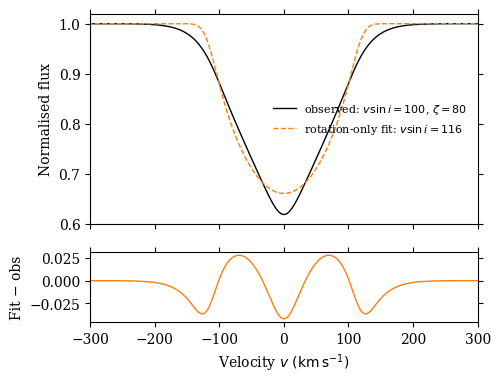

quadrature with k_sigma = 1.05 would give 131 km/s; the fit gives 116 km/s


In [10]:
R, pix = 22500, 4
idx = pixels(pix); vgrid, T = model_table(R, idx)
obs = observe(100, 80, R, idx)
vfit = fit_vsini(obs, vgrid, T)
best = T[np.searchsorted(vgrid, vfit)]; best = best * (best @ obs) / (best @ best)

fig, ax = plt.subplots(2, 1, figsize=(5, 4), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax[0].plot(V[idx], 1 - obs, 'k', lw=1, label=r'observed: $v\sin i=100$, $\zeta=80$')
ax[0].plot(V[idx], 1 - best, 'C1', lw=1, ls='--', label=rf'rotation-only fit: $v\sin i={vfit:.0f}$')
ax[1].plot(V[idx], best - obs, 'C1', lw=1)
ax[0].set_ylabel('Normalised flux'); ax[1].set_ylabel('Fit − obs')
ax[1].set_xlabel(r'Velocity $v~(\mathrm{km\,s^{-1}})$'); ax[1].set_xlim(-300, 300)
ax[0].legend(frameon=False, fontsize=8); plt.show()
print(f'quadrature with k_sigma = 1.05 would give {np.hypot(100, 1.054 * 80):.0f} km/s; the fit gives {vfit:.0f} km/s')

The rotation-only profile cannot reproduce the shape: it is too shallow at the centre, too steep at the edges and has
no wings, so the residuals are systematic. The fit settles on a width between the core and the wings, here 116 km/s,
well below the 131 km/s that matching the variance would give. Now we repeat this on a
grid of true $v\sin i$ and $\zeta$, then fit two candidate laws to the grid of fitted values:

* quadrature: $v\sin i_\mathrm{fit} = \sqrt{(v\sin i)^2 + k^2\zeta^2}$;
* linear: $v\sin i_\mathrm{fit} = v\sin i + c\,\zeta$.

In [11]:
VS = [0, 25, 50, 75, 100, 125, 150, 200, 300]
ZS = [0, 20, 40, 60, 80, 100]
PROF = {(v, z): disk_profile(v, z) for v in VS for z in ZS}       # computed once, reused below

def run_grid(R, pix, snr=None, nmc=1, seed=1):
    rng = np.random.default_rng(seed)
    idx = pixels(pix); vgrid, T = model_table(R, idx)
    rows = []
    for v in VS:
        for z in ZS:
            p = EW * conv(PROF[(v, z)], instrument(R))[idx]
            f = [fit_vsini(p + (rng.normal(0, 1 / snr, p.size) if snr else 0), vgrid, T) for _ in range(nmc)]
            rows.append((v, z, *np.percentile(f, [16, 50, 84])))
    return np.array(rows)          # columns: true vsini, zeta, fitted 16th, 50th, 84th percentile

def show(a):
    print('true vsini \\ zeta ' + ''.join(f'{z:>7d}' for z in ZS))
    for v in VS:
        print(f'{v:16d} ' + ''.join(f'{a[(a[:, 0] == v) & (a[:, 1] == z), 3][0]:7.0f}' for z in ZS))

def fit_laws(a, vmin=100):
    s = (a[:, 1] > 0) & (a[:, 0] >= vmin); v, z, f = a[s, 0], a[s, 1], a[s, 3]
    k2 = np.sum((f**2 - v**2) * z**2) / np.sum(z**4)                  # least squares in vfit^2
    c = np.sum((f - v) * z) / np.sum(z**2)
    rq = np.sqrt(np.mean((np.sqrt(v**2 + k2 * z**2) - f)**2)); rl = np.sqrt(np.mean((v + c * z - f)**2))
    print(f'v sin i >= {vmin}:  quadrature k = {np.sqrt(k2):.2f} (rms {rq:.1f} km/s)   linear c = {c:.2f} (rms {rl:.1f} km/s)')
    return np.sqrt(k2)

hi = run_grid(22500, 4)
show(hi); fit_laws(hi, 0); k_hi = fit_laws(hi, 100)

true vsini \ zeta       0     20     40     60     80    100
               0       0     19     34     47     61     75
              25      25     30     40     52     66     79
              50      50     52     58     67     78     90
              75      75     76     80     87     96    106
             100     100    101    104    109    116    124
             125     125    126    128    132    138    145
             150     150    150    152    156    161    168
             200     200    200    202    204    208    214
             300     300    300    301    303    306    309
v sin i >= 0:  quadrature k = 0.75 (rms 1.0 km/s)   linear c = 0.29 (rms 14.4 km/s)
v sin i >= 100:  quadrature k = 0.74 (rms 0.2 km/s)   linear c = 0.14 (rms 3.9 km/s)


The quadrature law describes the fitted values to about 1 km/s; a linear sum is an order of magnitude worse. At high
resolution $k \approx 0.75$, below the moment value 1.05 as expected.

Two consequences:

* At large $v\sin i$ the bias is small: $\sqrt{150^2 + (0.75\times80)^2} - 150 \approx 12$ km/s.
* At small $v\sin i$ the fitted value never drops below $\approx k\zeta$: a star with $\zeta = 80$ km/s cannot be
  fitted with $v\sin i$ much below 60 km/s, whatever its true rotation. **Subtracting $\zeta$ linearly from the fitted
  value is therefore wrong**: for $v\sin i_\mathrm{fit} = 116$ km/s and $\zeta = 80$ km/s it gives 36 km/s, while the
  true value is 100 km/s.

## 6. BOSS resolution, with noise

SDSS-V BOSS spectra have R ≈ 2000 (an instrumental FWHM of 150 km/s) and pixels of 69 km/s (Δlog λ = 10⁻⁴). We repeat
the grid without noise, then with S/N = 100 per pixel and 200 noise realisations per cell.

In [12]:
lo = run_grid(2000, 69)
show(lo); fit_laws(lo, 0); k_lo = fit_laws(lo, 100)

true vsini \ zeta       0     20     40     60     80    100
               0       0     21     41     60     78     96
              25      25     32     48     65     82     98
              50      50     54     64     77     92    106
              75      75     78     84     94    106    118
             100     100    102    107    114    124    134
             125     125    126    130    136    143    152
             150     150    151    154    158    164    172
             200     200    200    202    206    210    215
             300     300    300    301    303    306    309
v sin i >= 0:  quadrature k = 0.88 (rms 3.4 km/s)   linear c = 0.39 (rms 18.9 km/s)
v sin i >= 100:  quadrature k = 0.83 (rms 1.7 km/s)   linear c = 0.18 (rms 5.9 km/s)


In [13]:
lo_n = run_grid(2000, 69, snr=100, nmc=200)
show(lo_n); fit_laws(lo_n, 0); k_lo_n = fit_laws(lo_n, 100)

true vsini \ zeta       0     20     40     60     80    100
               0       0     19     43     62     79     94
              25      26     33     47     65     82     98
              50      51     55     63     78     92    105
              75      75     77     86     94    106    120
             100     100    102    106    114    124    134
             125     125    127    130    136    142    152
             150     150    151    153    159    164    173
             200     199    200    203    206    209    214
             300     300    301    302    301    307    307
v sin i >= 0:  quadrature k = 0.88 (rms 3.8 km/s)   linear c = 0.38 (rms 19.0 km/s)
v sin i >= 100:  quadrature k = 0.82 (rms 2.0 km/s)   linear c = 0.18 (rms 6.0 km/s)


At R = 2000 the quadrature law still holds (rms ≈ 2 km/s above 100 km/s), with a somewhat larger $k \approx 0.82$
above 100 km/s, and ≈ 0.88 over the whole grid: the broad instrumental profile makes the fit more sensitive to the
overall width, moving it towards the moment value. Noise adds scatter but no bias.

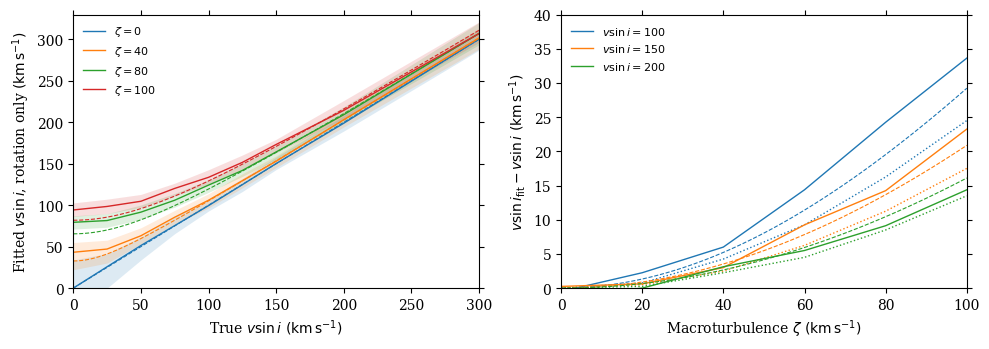

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
vt = np.linspace(0, 300, 301); zz = np.linspace(0, 100, 101)
for i, z in enumerate([0, 40, 80, 100]):
    s = lo_n[:, 1] == z
    ax[0].plot(lo_n[s, 0], lo_n[s, 3], color=f'C{i}', lw=1, label=rf'$\zeta={z}$')
    ax[0].fill_between(lo_n[s, 0], lo_n[s, 2], lo_n[s, 4], color=f'C{i}', alpha=0.15, lw=0)
    ax[0].plot(vt, np.sqrt(vt**2 + (k_lo_n * z)**2), color=f'C{i}', lw=0.8, ls='--')
ax[0].set_xlim(0, 300); ax[0].set_ylim(0, 330)
ax[0].set_xlabel(r'True $v\sin i~(\mathrm{km\,s^{-1}})$')
ax[0].set_ylabel(r'Fitted $v\sin i$, rotation only $(\mathrm{km\,s^{-1}})$')
ax[0].legend(frameon=False, fontsize=8, loc='upper left')
for i, v in enumerate([100, 150, 200]):
    s, h = lo_n[:, 0] == v, hi[:, 0] == v
    ax[1].plot(lo_n[s, 1], lo_n[s, 3] - v, color=f'C{i}', lw=1, label=rf'$v\sin i={v}$')
    ax[1].plot(hi[h, 1], hi[h, 3] - v, color=f'C{i}', lw=1, ls=':')
    ax[1].plot(zz, np.sqrt(v**2 + (k_lo_n * zz)**2) - v, color=f'C{i}', lw=0.8, ls='--')
ax[1].set_xlim(0, 100); ax[1].set_ylim(0, 40)
ax[1].set_xlabel(r'Macroturbulence $\zeta~(\mathrm{km\,s^{-1}})$')
ax[1].set_ylabel(r'$v\sin i_\mathrm{fit} - v\sin i~(\mathrm{km\,s^{-1}})$')
ax[1].legend(frameon=False, fontsize=8, loc='upper left'); plt.tight_layout(); plt.show()

Left: fitted against true $v\sin i$ at R = 2000, S/N = 100 (solid: median; band: 16–84%), with the quadrature law
(dashed). Right: the excess width against $\zeta$ for three rotation rates (solid: R = 2000; dotted: R = 22 500;
dashed: quadrature law with the R = 2000 value of $k$).

## 7. Does low resolution create a pile-up?

The Rix et al. BOSS validation against the IACOB O stars (Holgado et al. 2022) shows stars with true $v\sin i \lesssim
120$ km/s piling up at fitted values of 100–140 km/s. Can resolution and noise alone produce this? We fit noisy
R = 2000 profiles with $\zeta = 60$ km/s at lower S/N.

In [15]:
idx = pixels(69); vgrid, T = model_table(2000, idx); rng = np.random.default_rng(2)
for snr in [100, 30, 15]:
    print(f'S/N = {snr}')
    for v in [0, 50, 100, 150]:
        p = observe(v, 60, 2000, idx)
        f = [fit_vsini(p + rng.normal(0, 1 / snr, p.size), vgrid, T) for _ in range(300)]
        q = np.percentile(f, [16, 50, 84])
        print(f'   true {v:3d} -> fitted {q[1]:4.0f}  [{q[0]:3.0f}, {q[2]:3.0f}]')

S/N = 100


   true   0 -> fitted   60  [ 49,  71]


   true  50 -> fitted   78  [ 67,  87]


   true 100 -> fitted  114  [105, 121]


   true 150 -> fitted  158  [150, 168]
S/N = 30


   true   0 -> fitted   61  [  0,  92]


... (3 outputs left out)

   true   0 -> fitted   60  [  0, 123]


   true  50 -> fitted   78  [  0, 130]


   true 100 -> fitted  105  [ 37, 161]


   true 150 -> fitted  164  [103, 226]


No: the medians stay at the noiseless values of Section 6 (60, 77, 114 and 158 km/s for $\zeta = 60$) and only the
scatter grows as S/N drops. Nothing clusters at 130 km/s. A pile-up there must come from the pipeline itself (for example a lower bound of its model grid or a
prior), and has to be taken from an empirical validation.

## 8. How much does the assumption $A_R = A_T$ matter?

Everything above assumed equal radial and tangential fractions. That is a convention, not a measurement. The
velocity field could be dominated by horizontal motions, as for low-frequency gravity waves and g modes, whose
horizontal displacement exceeds the radial one by about $GM/(\omega^2R^3) \gg 1$ at the surface. Or it could be
dominated by radial motions, as in convective up- and downflows. We repeat the calculation for $A_R$ from 0 (purely
tangential) to 1 (purely radial).

**Variance.** With $A_R \neq A_T$ the local variance depends on $\mu$, so limb darkening enters through the
intensity-weighted mean of $\mu^2$ over the disk:

$$
\sigma^2_\mathrm{mac} = \frac{\zeta^2}{2}\left[A_R\langle\mu^2\rangle + A_T\left(1-\langle\mu^2\rangle\right)\right].
$$

In [16]:
mu2 = sp.integrate((1 - eps + eps * mu) * mu**3, (mu, 0, 1)) / sp.integrate((1 - eps + eps * mu) * mu, (mu, 0, 1))
display(sp.Eq(sp.Symbol(r'\langle\mu^2\rangle'), sp.factor(mu2)))
m2v = float(mu2.subs(eps, sp.Rational(3, 5))); print(f'<mu^2> at eps = 0.6: {m2v:.3f}')
for a in [0, 0.5, 1]:
    pred = 0.5 * (a * m2v + (1 - a) * (1 - m2v))
    meas = (variance(disk_profile(100, 80, a)) - variance(disk_profile(100, 0, a))) / 80**2
    print(f'A_R = {a:3.1f}:  sigma_mac^2 / zeta^2 = {pred:.4f} (formula), {meas:.4f} (profile)')

Eq(\langle\mu^2\rangle, 3*(epsilon - 5)/(10*(epsilon - 3)))

<mu^2> at eps = 0.6: 0.550


A_R = 0.0:  sigma_mac^2 / zeta^2 = 0.2250 (formula), 0.2247 (profile)


A_R = 0.5:  sigma_mac^2 / zeta^2 = 0.2500 (formula), 0.2500 (profile)


A_R = 1.0:  sigma_mac^2 / zeta^2 = 0.2750 (formula), 0.2753 (profile)


In variance the cases differ by only ±10%, i.e. ±5% in width. If fits matched variances, $A_R$ would hardly
matter. They do not, because the shapes differ:

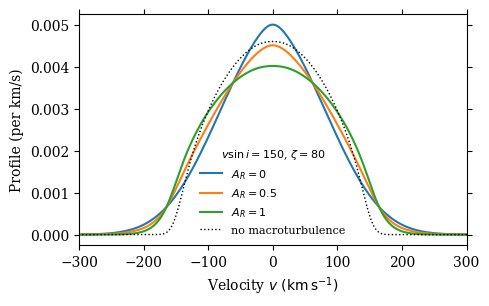

In [17]:
fig, ax = plt.subplots(figsize=(5, 3))
for i, a in enumerate([0, 0.5, 1]):
    ax.plot(V, disk_profile(150, 80, a) / dv, color=f'C{i}', label=rf'$A_R={a}$')
ax.plot(V, disk_profile(150, 0) / dv, 'k:', lw=1, label=r'no macroturbulence')
ax.set_xlim(-300, 300); ax.set_xlabel(r'Velocity $v~(\mathrm{km\,s^{-1}})$'); ax.set_ylabel('Profile (per km/s)')
ax.legend(frameon=False, fontsize=8, title=r'$v\sin i=150$, $\zeta=80$', title_fontsize=8); plt.show()

Radial motions are seen mostly near disk centre, where the line forms at small rotational shifts: they widen and
flatten the core of the profile, which a rotation-only fit reads as faster rotation. Tangential motions are seen
mostly near the limb, which includes the edges of the profile at $\pm v\sin i$: they spread light from the edges
both outwards (wings) and inwards (the centre becomes more peaked), so the half-width barely changes. A rotation-only
fit therefore largely ignores tangential macroturbulence once $v\sin i \gg \zeta$.

The fitted excess $v\sin i_\mathrm{fit} - v\sin i$ at R = 2000 (no noise) shows this:

In [18]:
idx = pixels(69); vgrid, T = model_table(2000, idx)
print('true vsini/zeta  ' + ''.join(f'{f"{v}/{z}":>8s}' for v in [0, 50, 100, 150, 200] for z in [40, 80]))
for a in [0, 0.5, 1]:
    row = [fit_vsini(EW * conv(disk_profile(v, z, a), instrument(2000))[idx], vgrid, T) - v
           for v in [0, 50, 100, 150, 200] for z in [40, 80]]
    print(f'A_R = {a:3.1f} excess ' + ''.join(f'{x:+8.0f}' for x in row))

true vsini/zeta      0/40    0/80   50/40   50/80  100/40  100/80  150/40  150/80  200/40  200/80


A_R = 0.0 excess      +39     +74     +12     +36      +4     +16      +1      +6      +0      +1


A_R = 0.5 excess      +41     +78     +14     +42      +7     +24      +4     +14      +2     +10


A_R = 1.0 excess      +43     +82     +16     +47      +9     +30      +6     +22      +5     +18


Without rotation all three give similar excesses: any macroturbulence broadens a narrow line. Above 100 km/s they
diverge. For $v\sin i = 150$ km/s and $\zeta = 80$ km/s the excess is about 6, 14 and 22 km/s for $A_R$ = 0, 1/2
and 1. For a purely tangential field the excess nearly vanishes at high $v\sin i$, so the quadrature law no longer
describes it well.

**Two values of $k$.** What enters the forward model is not the true $\zeta$ but the $\zeta$ that IACOB measured,
*assuming* $A_R = A_T$. If the real field has another $A_R$, that measurement already absorbs part of the
difference. We mimic it: a high-resolution spectrum (R = 46 000), $v\sin i$ known (IACOB takes it from the Fourier
transform), and $\zeta$ fitted with the $A_R = 1/2$ model. Then we fit $k$ for $v\sin i \ge 100$ km/s twice:
relative to the true $\zeta$, and relative to the IACOB-style $\zeta$. This cell takes a few minutes.

In [19]:
ARS = [0.0, 0.25, 0.5, 0.75, 1.0]; VK = [100, 150, 200]; ZK = [40, 80]
PA = {(v, z, a): disk_profile(v, z, a) for v in VK for z in ZK for a in ARS}

# IACOB-style zeta: R = 46000, 2 km/s pixels, vsini fixed, zeta fitted with the A_R = 1/2 model
idx_h = pixels(2); zgrid = np.arange(0, 160.01, 2.0); zeta_iacob = {}
for v in VK:
    Tz = np.array([conv(disk_profile(v, zz, 0.5), instrument(46000))[idx_h] for zz in zgrid])
    for z in ZK:
        for a in ARS:
            zeta_iacob[(v, z, a)] = fit_vsini(EW * conv(PA[(v, z, a)], instrument(46000))[idx_h], zgrid, Tz)

def k_of(R, pix, a, zeta_ref):
    idx = pixels(pix); vgrid, T = model_table(R, idx); num = den = 0.0
    for v in VK:
        for z in ZK:
            f = fit_vsini(EW * conv(PA[(v, z, a)], instrument(R))[idx], vgrid, T); zr = zeta_ref(v, z, a)
            num += (f**2 - v**2) * zr**2; den += zr**4
    return np.sqrt(max(num, 0) / den)

print(' A_R   zeta_IACOB/zeta   k(R=2000) vs true zeta   k(R=2000) vs IACOB zeta')
kA = {}
for a in ARS:
    ratio = np.median([zeta_iacob[(v, z, a)] / z for v in VK for z in ZK])
    k_true = k_of(2000, 69, a, lambda v, z, a: z)
    kA[a] = k_of(2000, 69, a, lambda v, z, a: zeta_iacob[(v, z, a)])
    print(f'{a:5.2f}   {ratio:15.2f}   {k_true:22.2f}   {kA[a]:23.2f}')

 A_R   zeta_IACOB/zeta   k(R=2000) vs true zeta   k(R=2000) vs IACOB zeta


 0.00              1.06                     0.56                      0.52


 0.25              1.01                     0.72                      0.71


 0.50              1.00                     0.85                      0.85


 0.75              0.99                     0.96                      0.94


 1.00              0.94                     1.06                      0.99


**The size of the error.** The IACOB measurement itself is only mildly affected (ζ changes by at most 6%), but the
bias of a rotation-only fit is not. Relative to the IACOB ζ, the BOSS value of $k$ runs from about 0.5 (purely
tangential) through 0.85 (equal fractions) to about 1.0 (purely radial), and lies in 0.71–0.94 for
$0.25 \le A_R \le 0.75$. So the assumption $A_R = A_T$ carries a systematic uncertainty in $k$ of about
$-0.14/+0.09$, and up to a factor of 1.6 if the field is purely horizontal. The excess width scales as $k^2$ when
$v\sin i \gg k\zeta$, so the uncertainty in the excess is a factor of about 0.7–1.2, and up to about 2.7 lower
for a purely tangential field. (These $k$ values come from a smaller grid than Section 6, so the equal-fraction value
differs slightly from the 0.82 found there.)

This also turns the empirical calibration into a measurement. The value of $k$ fitted from stars with known
$v\sin i$ and ζ (for example the Rix et al. versus Holgado et al. comparison) constrains the geometry of the
velocity field: $k \approx 0.8$ is consistent with equal fractions, while $k \lesssim 0.5$ would point to a mostly
horizontal field.

## Summary

* Variances add exactly, so the extra width from macroturbulence adds **in quadrature**, not linearly. For
  $A_R = A_T$ the macroturbulent variance is $\zeta^2/4$ at every point on the disk.
* A least-squares rotation-only fit returns $v\sin i_\mathrm{fit} \simeq \sqrt{(v\sin i)^2 + k^2\zeta^2}$, with
  $k \approx 0.75$ at R = 22 500 and $k \approx 0.82$ (above 100 km/s) to 0.88 (whole grid) at R = 2000. The
  moment value $k_\sigma = 1.05$ is an upper bound.
* Above ~150 km/s the bias is ≲ 10–15 km/s even for $\zeta = 80$–100 km/s; below ~100 km/s the fitted value is set
  largely by $\zeta$.
* These values assume equal radial and tangential fractions. Relative to the IACOB ζ, $k$ at R = 2000 ranges from
  ≈ 0.5 (purely tangential, as for gravity waves) to ≈ 1.0 (purely radial), and ≈ 0.71–0.94 for
  $0.25 \le A_R \le 0.75$. An empirical $k$ therefore also constrains the geometry of the macroturbulent field.

**What this model leaves out:** a single weak line rather than a full-spectrum fit; Gaussian intrinsic profiles (no
Stark wings of H and He lines); the same limb darkening in data and model. The functional form is
robust to these, but the value of $k$ for a given pipeline should be calibrated on stars with independently measured
$v\sin i$ and $\zeta$ (e.g. the IACOB stars observed by SDSS-V).